# Retail Sales & Shopper Analytics using SQL
**Goal:** compute the core retail-measurement metrics (market share, growth, top products, shopper repeat rate, basket size) from raw transactions, mostly in SQL, and check the data for problems that would mislead a reader.

**Dataset:** UCI Online Retail, ~541K transactions from a UK online retailer, Dec 2010 to Dec 2011.

Run each cell from top to bottom (Shift + Enter).

## 1. Load the data

In [1]:
import pandas as pd, numpy as np, sqlite3
import matplotlib.pyplot as plt

URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/00352/Online%20Retail.xlsx"
raw = pd.read_excel(URL)   # takes 1-2 minutes

raw["InvoiceNo"] = raw["InvoiceNo"].astype(str)
raw["StockCode"] = raw["StockCode"].astype(str)
raw["InvoiceDate"] = pd.to_datetime(raw["InvoiceDate"]).dt.strftime("%Y-%m-%d %H:%M:%S")
print(raw.shape)
raw.head()

(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 2. Load into a SQL database

In [2]:
con = sqlite3.connect(":memory:")
raw.to_sql("raw_sales", con, index=False)
def q(sql):
    return pd.read_sql_query(sql, con)
print("Loaded rows:", q("SELECT COUNT(*) AS n FROM raw_sales")["n"][0])

Loaded rows: 541909


## 3. Data quality check (before trusting any number)

In [3]:
q('''
SELECT
  COUNT(*)                                              AS total_rows,
  SUM(CASE WHEN InvoiceNo LIKE 'C%' THEN 1 ELSE 0 END)  AS cancellations,
  SUM(CASE WHEN Quantity <= 0 THEN 1 ELSE 0 END)        AS non_positive_qty,
  SUM(CASE WHEN UnitPrice <= 0 THEN 1 ELSE 0 END)       AS non_positive_price,
  SUM(CASE WHEN CustomerID IS NULL THEN 1 ELSE 0 END)   AS missing_customer
FROM raw_sales
''')

,total_rows,cancellations,non_positive_qty,non_positive_price,missing_customer
0,541909,9288,10624,2517,135080


## 4. Clean in SQL and add revenue

In [4]:
con.executescript('''
DROP TABLE IF EXISTS sales;
CREATE TABLE sales AS
SELECT InvoiceNo, StockCode, Description, Quantity, UnitPrice, CustomerID, Country, InvoiceDate,
       Quantity * UnitPrice              AS Revenue,
       substr(InvoiceDate, 1, 7)         AS Month,
       strftime('%Y-%W', InvoiceDate)    AS Week
FROM raw_sales
WHERE InvoiceNo NOT LIKE 'C%' AND Quantity > 0 AND UnitPrice > 0;
''')
q("SELECT COUNT(*) AS clean_rows, COUNT(DISTINCT CustomerID) AS customers, COUNT(DISTINCT Country) AS countries, ROUND(SUM(Revenue)) AS revenue FROM sales")

,clean_rows,customers,countries,revenue
0,530104,4338,38,10666685.0


## 5. Market share by country (window function)

In [5]:
share = q('''
SELECT Country,
       ROUND(SUM(Revenue))                                       AS revenue,
       ROUND(100.0 * SUM(Revenue) / SUM(SUM(Revenue)) OVER (), 2) AS share_pct
FROM sales
GROUP BY Country
ORDER BY revenue DESC
LIMIT 10
''')
share

,Country,revenue,share_pct
0,United Kingdom,9025222.0,84.61
1,Netherlands,285446.0,2.68
2,EIRE,283454.0,2.66
3,Germany,228867.0,2.15
4,France,209715.0,1.97
5,Australia,138521.0,1.30
6,Spain,61577.0,0.58
7,Switzerland,57090.0,0.54
8,Belgium,41196.0,0.39
9,Sweden,38378.0,0.36


## 6. Monthly sales and month-on-month growth (LAG)

,Month,revenue,trading_days,mom_growth_pct
0,2010-12,823746.0,20,NaN
1,2011-01,691365.0,24,-16.1
2,2011-02,523632.0,24,-24.3
3,2011-03,717639.0,27,37.1
4,2011-04,537809.0,21,-25.1
5,2011-05,770536.0,25,43.3
6,2011-06,761740.0,26,-1.1
7,2011-07,719221.0,26,-5.6
8,2011-08,759138.0,26,5.6
9,2011-09,1058590.0,26,39.4


Check: the last month has far fewer trading days (data ends 9 Dec 2011),
so its 'drop' is a partial-period effect, not a real decline.


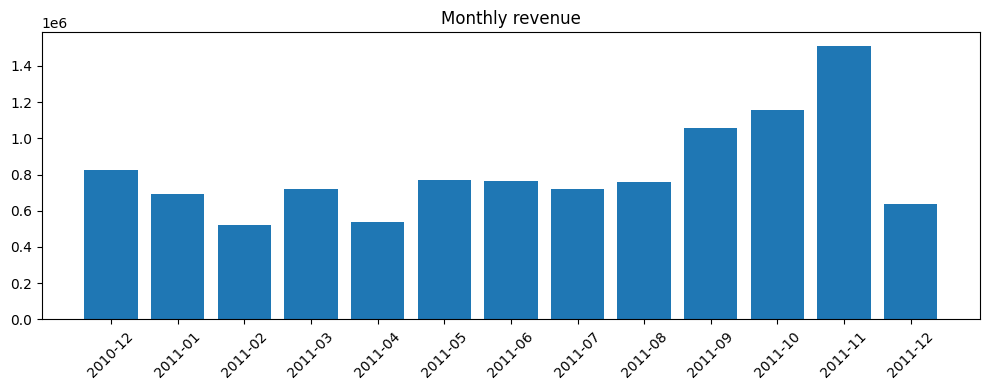

In [6]:
monthly = q('''
WITH m AS (
  SELECT Month, SUM(Revenue) AS revenue, COUNT(DISTINCT substr(InvoiceDate,1,10)) AS trading_days
  FROM sales GROUP BY Month
)
SELECT Month, ROUND(revenue) AS revenue, trading_days,
       ROUND(100.0 * (revenue - LAG(revenue) OVER (ORDER BY Month)) / LAG(revenue) OVER (ORDER BY Month), 1) AS mom_growth_pct
FROM m ORDER BY Month
''')
display(monthly)
print("Check: the last month has far fewer trading days (data ends 9 Dec 2011),")
print("so its 'drop' is a partial-period effect, not a real decline.")

plt.figure(figsize=(10,4))
plt.bar(monthly["Month"], monthly["revenue"])
plt.xticks(rotation=45); plt.title("Monthly revenue"); plt.tight_layout(); plt.show()

## 7. Top products, and top 3 per country (RANK)
**Data check:** my first ranking was topped by rows like *DOTCOM POSTAGE*, *Manual* and *POSTAGE*. These are shipping fees and manual adjustments, not products, so they are excluded below. Without this step, the 'best-selling product' would have been postage.

In [7]:
NON_PRODUCT = "('POST','DOT','M','m','C2','D','S','B','CRUK','PADS','BANK CHARGES','AMAZONFEE')"

# How much revenue do these non-product rows carry?
display(q(f'''
SELECT StockCode, Description, ROUND(SUM(Revenue)) AS revenue
FROM sales WHERE StockCode IN {NON_PRODUCT}
GROUP BY StockCode, Description ORDER BY revenue DESC
'''))

# Top 10 real products
display(q(f'''
SELECT StockCode, Description, ROUND(SUM(Revenue)) AS revenue, SUM(Quantity) AS units
FROM sales
WHERE StockCode NOT IN {NON_PRODUCT}
GROUP BY StockCode, Description ORDER BY revenue DESC LIMIT 10
'''))

# Top 3 real products per country
q(f'''
WITH p AS (
  SELECT Country, Description, SUM(Revenue) AS revenue,
         RANK() OVER (PARTITION BY Country ORDER BY SUM(Revenue) DESC) AS rnk
  FROM sales
  WHERE StockCode NOT IN {NON_PRODUCT}
  GROUP BY Country, Description
)
SELECT Country, rnk, Description, ROUND(revenue) AS revenue
FROM p WHERE rnk <= 3 AND Country IN ('United Kingdom','Germany','France','EIRE')
ORDER BY Country, rnk
''')

,StockCode,Description,revenue
0,DOT,DOTCOM POSTAGE,206249.0
1,M,Manual,78110.0
2,POST,POSTAGE,78102.0
3,AMAZONFEE,AMAZON FEE,13761.0
4,B,Adjust bad debt,11062.0
5,C2,CARRIAGE,7051.0
6,BANK CHARGES,Bank Charges,165.0
7,S,SAMPLES,63.0
8,m,Manual,3.0
9,PADS,PADS TO MATCH ALL CUSHIONS,0.0


,StockCode,Description,revenue,units
0,22423,REGENCY CAKESTAND 3 TIER,174485.0,13879
1,23843,"PAPER CRAFT , LITTLE BIRDIE",168470.0,80995
2,85123A,WHITE HANGING HEART T-LIGHT HOLDER,104340.0,37599
3,47566,PARTY BUNTING,99504.0,18295
4,85099B,JUMBO BAG RED RETROSPOT,94340.0,48474
5,23166,MEDIUM CERAMIC TOP STORAGE JAR,81701.0,78033
6,23084,RABBIT NIGHT LIGHT,66965.0,30788
7,22086,PAPER CHAIN KIT 50'S CHRISTMAS,64952.0,19355
8,84879,ASSORTED COLOUR BIRD ORNAMENT,59095.0,36461
9,79321,CHILLI LIGHTS,54118.0,10306


,Country,rnk,Description,revenue
0,EIRE,1,REGENCY CAKESTAND 3 TIER,7844.0
1,EIRE,2,3 TIER CAKE TIN RED AND CREAM,4266.0
2,EIRE,3,JAM MAKING SET WITH JARS,3098.0
3,France,1,RABBIT NIGHT LIGHT,7277.0
4,France,2,REGENCY CAKESTAND 3 TIER,2817.0
5,France,3,RED TOADSTOOL LED NIGHT LIGHT,2170.0
6,Germany,1,REGENCY CAKESTAND 3 TIER,9062.0
7,Germany,2,ROUND SNACK BOXES SET OF4 WOODLAND,3599.0
8,Germany,3,ROUND SNACK BOXES SET OF 4 FRUITS,1982.0
9,United Kingdom,1,"PAPER CRAFT , LITTLE BIRDIE",168470.0


## 8. Shopper metrics: penetration, repeat rate, basket size

In [8]:
q('''
WITH c AS (
  SELECT CustomerID, COUNT(DISTINCT InvoiceNo) AS baskets, SUM(Revenue) AS spend
  FROM sales WHERE CustomerID IS NOT NULL GROUP BY CustomerID
),
b AS (
  SELECT InvoiceNo, SUM(Revenue) AS basket_value, SUM(Quantity) AS basket_units
  FROM sales GROUP BY InvoiceNo
)
SELECT
  (SELECT COUNT(*) FROM c)                                             AS customers,
  ROUND(100.0 * (SELECT COUNT(*) FROM c WHERE baskets >= 2) / (SELECT COUNT(*) FROM c), 1) AS repeat_rate_pct,
  ROUND((SELECT AVG(baskets) FROM c), 2)                               AS avg_baskets_per_customer,
  ROUND((SELECT AVG(basket_value) FROM b), 2)                          AS avg_basket_value,
  ROUND((SELECT AVG(basket_units) FROM b), 1)                          AS avg_units_per_basket
''')

,customers,repeat_rate_pct,avg_baskets_per_customer,avg_basket_value,avg_units_per_basket
0,4338,65.6,4.27,534.4,280.0


## 9. Flag unusual weeks (data quality check)

,Week,revenue,rolling_mean,rolling_std,z
16,2011-13,192720.480,138100.223750,16820.582338,3.247227
20,2011-17,86465.080,149714.023875,19960.508207,-3.168704
22,2011-19,211984.260,145397.598875,29638.475871,2.246629
40,2011-37,230137.260,179213.055125,15904.534570,3.201867
41,2011-38,338771.791,182684.520125,23088.364638,6.760430
48,2011-45,370044.970,271072.840250,46361.501530,2.134791
52,2011-49,504309.930,308417.057500,53763.996895,3.643570


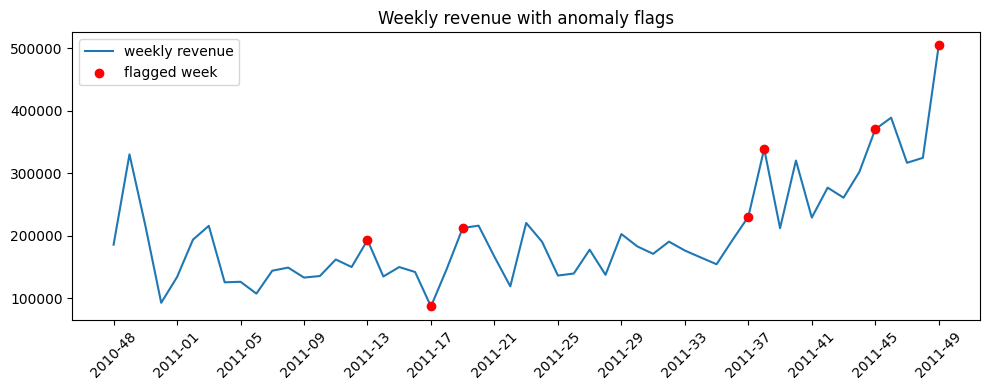

In [9]:
weekly = q("SELECT Week, SUM(Revenue) AS revenue FROM sales GROUP BY Week ORDER BY Week")
weekly["rolling_mean"] = weekly["revenue"].rolling(8, min_periods=4).mean().shift(1)
weekly["rolling_std"]  = weekly["revenue"].rolling(8, min_periods=4).std().shift(1)
weekly["z"] = (weekly["revenue"] - weekly["rolling_mean"]) / weekly["rolling_std"]
flags = weekly[weekly["z"].abs() > 2]
display(flags)

plt.figure(figsize=(10,4))
plt.plot(weekly["Week"], weekly["revenue"], label="weekly revenue")
plt.scatter(flags["Week"], flags["revenue"], color="red", zorder=3, label="flagged week")
plt.xticks(weekly["Week"][::4], rotation=45); plt.legend(); plt.title("Weekly revenue with anomaly flags")
plt.tight_layout(); plt.show()

## 10. Findings and limits
- **The United Kingdom dominates:** 84.6% of revenue (about £9.0M of £10.7M). The next markets, the Netherlands (2.7%) and EIRE (2.7%), are far behind.
- **Strong year-end seasonality:** revenue rose from about £0.76M in August 2011 to a peak of £1.51M in November 2011.
- **The December 2011 'drop' of 57.7% is not real:** the data ends on 9 December, so that month has only 8 trading days versus about 26 in a normal month.
- **Shoppers:** 65.6% of the 4,338 identified customers bought more than once; the average basket is worth about £534 with about 280 units, which suggests many customers are wholesalers rather than individual shoppers.
- **Data issues found:** about 25% of rows (135,080) have no customer ID; 9,288 rows are cancellations; and non-product rows (postage, manual adjustments) had to be removed before ranking products.
- **Unusual weeks:** the largest spike was week 38 of 2011 (z-score 6.8), at the start of the pre-Christmas ramp-up.

**Limits:** this is one retailer, not a whole market, and shopper metrics cover only customers with an ID.